<div align="center">
    
# ΠΑΝΕΠΙΣΤΗΜΙΟ ΚΡΗΤΗΣ
# Τμήμα Επιστήμης Υπολογιστών

## HY-112: Φυσική Ι
## Χειμερινό Εξάμηνο 2023-2024
### Διδάσκων: Γ. Καφεντζής

## Ανάθεση: 10-12-2024
## Παράδοση (ηλεκτρονικά, όπως αναφέρεται στο τέλος του αρχείου): 
## Κυριακή, 22-12-2024, 23:59:59

Σε αυτο το πέμπτο "εργαστήριο" του μαθήματος θα πειραματιστούμε με (α) το φαινόμενο Doppler και (β) υπέρθεση κυμάτων (στάσιμων και μη).

Σε κάθε πρόγραμμα Python που γράφουμε, στις πρώτες γραμμές εισάγουμε όποιες βιβλιοθήκες σκοπεύουμε να χρησιμοποιήσουμε. 

Ας ξεκινήσουμε εισάγοντας τις γνωστές μας βιβλιοθήκες, και κάποιες βολικές συντομεύσεις τους. Εκτελέστε το παρακάτω κομμάτι κώδικα επιλέγοντάς το και πατώντας Shift + Enter.

In [3]:
import numpy as np                      # Βιβλιοθήκη numpy, θα τη "φωνάζουμε" ως np στο εξής.
import matplotlib.pyplot as plt         # Θέλουμε μόνο την pyplot βιβλιοθήκη της βιβλιοθήκης matplotlib και θα τη "φωνάζουμε" plt.
from IPython.display import Audio       # Βιβλιοθήκη για να "παίζουμε" ήχους (μεταξύ άλλων).
from scipy.io import wavfile            # Βιβλιοθήκη για να "διαβάζουμε" .wav files (μεταξύ άλλων).
import ipywidgets as widgets            # Βιβλιοθήκη για animations και interaction με το χρήστη.
from IPython.display import display     # Βιβλιοθήκη για οπτικοποίηση.
%matplotlib inline

# Άσκηση Python 1

Σε αυτήν την άσκηση θα μελετήσουμε πιο πρακτικά το φαινόμενο Doppler και θα το δούμε να δουλεύει στην πράξη. 

Στο μάθημα μελετήσαμε τα θεωρητικά στοιχεία σχετικά με το φαινόμενο Doppler, και σε όλες τις περιπτώσεις υποθέσαμε ότι παρατηρητής και πηγή ήχου βρίσκονται στην ίδια ευθεία. Αυτή είναι μια βολική παραδοχή γιατί μας επιτρέπει να χρησιμοποιήσουμε τις εξισώσεις Doppler όπως τις είδαμε στο μάθημα:

$$f' = \frac{u \pm u_o}{u \mp u_s}f$$

με $u$ την ταχύτητα του ήχου, $u_o$ η ταχύτητα του παρατηρητή, $u_s$ η ταχύτητα της πηγής ήχου, $f'$ η συχνότητα που ακούμε και $f$ η συχνότητα που παράγει η πηγή ήχου.

Ας υποθέσουμε ότι ο παρατηρητής είναι ακίνητος και η πηγή κινείται **προς** τον παρατηρητή. Πηγή και παρατηρητής βρίσκονται στην ίδια ευθεία. Τότε

$$f' = \frac{u}{u - u_s}f$$

Ας γράψουμε κώδικα που υλοποιεί το φαινόμενο Doppler, υποθέτοντας ότι η πηγή βρίσκεται μακριά μας και μας πλησιάζει, και στη συνέχεια απομακρύνεται από μας. Η ταχύτητα της πηγής θα είναι $u_s=20$ m/s και η ταχύτητα του ήχου θα είναι $u = 340$ m/s. Συχνότητα της πηγής θα είναι $f = 440$ Hz.

### Ζητούμενο 1:

Συμπληρώστε τον παρακάτω κώδικα, όπου υπολογίζεται η συχνότητα μιας ηχητικής πηγής που μας πλησιάζει.

In [5]:
f = 440.0                      # Συχνότητα πηγής.
u = 340.0                      # Ταχύτητα ήχου.
us = 20.0                      # Ταχύτητα πηγής.
fnew = ((u * f) / (u - us))    # Doppler effect.

Ας τα ακούσουμε - την ακίνητη πηγή πρώτα! - **ΜΗ** δώσετε σημασία στο τεχνικό κομμάτι των παρακάτω - αποτελούν ύλη άλλου μαθήματος - απλώς εκτελέστε τα παρακάτω δυο κελιά κώδικα.

In [ ]:
fs = 44100     # Συχνότητα δειγματοληψίας.
print("Η συχνότητα που ακούμε από ακίνητη πηγή θα είναι {}".format(f))   # Πρέπει να πάρετε: f = 440.0 Hz

In [ ]:
n = np.arange(0, 100000)       # Διάνυσμα διακριτού χρόνου.
w0 = 2 * np.pi * f / fs        # "Διακριτή συχνότητα" ακίνητης πηγής.
output = np.cos(w0 * n)        # Ημίτονο !
Audio(output, rate=fs)         # Ακούμε! :)

Ας ακουσουμε και τη μετατοπισμένη λόγω Doppler συχνότητα! Ξανά, απλώς εκτελέστε τα δυο κελιά.

In [ ]:
fs = 44100     # Συχνότητα δειγματοληψίας.
print("Η συχνότητα που ακούμε λόγω του φαινομένου Doppler θα είναι {}".format(fnew))   # Πρέπει να πάρετε: fnew = 467.5 Hz

In [ ]:
n = np.arange(0, 100000)            # Διάνυσμα διακριτού χρόνου.
w0new = 2 * np.pi * fnew / fs       # "Διακριτή" συχνότητα κινούμενης πηγής.
output = np.cos(w0new * n)          # Ημίτονο !
Audio(output, rate=fs)              # Ακούμε! :)

Ας υποθέσουμε ότι ο παρατηρητής είναι ακίνητος και η πηγή κινείται **απομακρυνόμενη** από τον παρατηρητή, με τους δυο να βρίσκονται ξανά στην ίδια ευθεία. Συμπληρώστε το παρακάτω κομμάτι κώδικα:

In [ ]:
f = 440.0                         # Συχνότητα πηγής.
u = 340.0                         # Ταχύτητα ήχου.
us = 20.0                         # Ταχύτητα πηγής.
fnew = ((u * f) / (u + us))       # Doppler effect απομακρυνόμενης πηγής.

Ας το ακούσουμε (απλώς εκτελέστε τα δυο κελιά).

In [ ]:
fs = 44100     # Συχνότητα δειγματοληψίας.
print("Η συχνότητα που ακούμε από απομακρυνόμενη πηγή θα είναι {}".format(fnew))   # Πρέπει να πάρετε: fnew = 415.5 Hz

In [ ]:
n = np.arange(0, 100000)            # Διάνυσμα διακριτού χρόνου.
w0new = 2 * np.pi * fnew / fs       # "Διακριτή συχνότητα".
output = np.cos(w0new * n)          # Ημίτονο !
Audio(output, rate=fs)              # Ακούμε! :)

#### **Μπορείτε να ακούσετε τη διαφορά μεταξύ αυτών των τριών συχνοτήτων?**

***
***
Ένας παράγοντας που *δεν* εξετάσαμε στο μάθημα είναι η περίπτωση ο παρατηρητής και η πηγή να **μη** βρίσκονται στην ίδια ευθεία. Όταν λοιπόν πηγή και παρατηρητής **δε** βρίσκονται στην ίδια ευθεία, η μεταβλητή $u_s$ (που αποτελεί την ταχύτητα της πηγής ήχου) αντικαθίσται από τη μεταβλητή

$$ u_r = u_s \cos(\theta) $$

με $u_r$ η περίφημη **ακτινική ταχύτητα (radial velocity)** και $\theta$ η γωνία μεταξύ του διανύσματος της ταχύτητας $u_s$ της πηγής και του διανύσματος που ενώνει την κινούμενη πηγή με τον παρατηρητή. Τότε η εξίσωση Doppler μετατρέπεται ως 

$$f' = \frac{u}{u - u_r}f = \frac{u}{u - u_s \cos(\theta)}f$$

Στην περίπτωση αυτή, αφήνουμε το πρόσημο του $\cos(\theta)$ να αλλάξει το πρόσημο του δεύτερου όρου του παρονομαστή, δηλ. δεν έχουμε δυο διαφορετικές σχέσεις (μια για προσέγγιση της πηγής στον ακροατή και μια για απομάκρυνση αυτής από τον ακροατή) όπως είχαμε δείξει στη θεωρία. 

Θέσετε, για παράδειγμα $\theta = 0$ (ο παρατηρητής και η πηγή βρίσκονται στην ίδια ευθεία, με την πηγή να τον πλησιάζει): έχετε τη σχέση που είδατε στη θεωρία: 

$$f' = \frac{u}{u - u_s\cdot 1}f = \frac{u}{u - u_s}f$$

Θέσετε τώρα $\theta = \pi$ (ο παρατηρητής και η πηγή βρίσκονται στην ίδια ευθεία, με την πηγή να απομακρύνεται από τον παρατηρητή), και δείτε ξανά τη σχέση που είδατε στη θεωρία:

$$f' = \frac{u}{u - u_s(-1)}f = \frac{u}{u + u_s}f$$

Κρατούμε και δουλεύουμε λοιπόν τη γενική σχέση

$$f' = \frac{u}{u - u_s \cos(\theta)}f$$

Ας υποθέσουμε ότι οδηγείτε με το αυτοκίνητό σας και σταματάτε σε μια σιδηροδρομική γραμμή, μακριά από τη διασταύρωση. Η σιδηροδρομική γραμμή είναι ευθεία και κάθετη στο δρόμο πάνω στον οποίο βρίσκεστε. Με άλλα λόγια, βρίσκεστε σε μια κατάσταση όπως στο παρακάτω σχήμα.

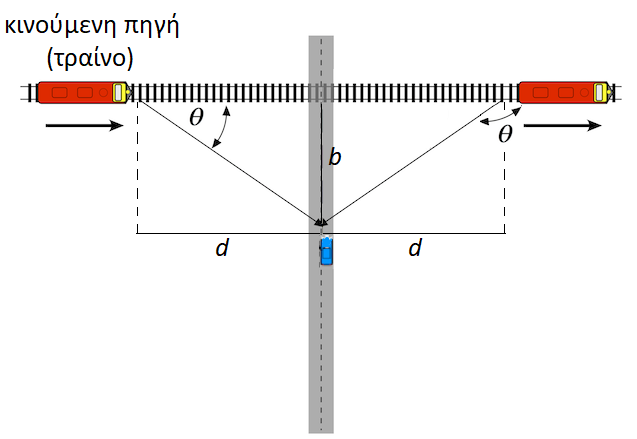

Σε αυτήν την κατάσταση, αν θέλετε να βρείτε τη συχνότητα που θα ακούσετε από το διερχόμενο τραίνο δεν είναι σωστό να χρησιμοποιήσετε την εξίσωση Doppler που είδαμε στη θεωρία. Αυτή ισχύει μόνο αν βρίσκεστε επάνω στη σιδηροδρομική τροχιά (και τότε η συχνότητα της κόρνας του τραίνου θα είναι το τελευταίο που θα σας απασχολεί 😃). Ευτυχώς βρίσκεστε σε κάθετη απόσταση $b$ από τις σιδηροτροχιές και το τραίνο έρχεται προς εσάς υπό γωνία $\theta$ που προφανώς μεταβάλλεται συνεχώς όσο το τραίνο πλησιάζει.

Καταλαβαίνετε ότι επειδή η γωνία $\theta$ μεταβάλλεται, μεταβάλλεται επίσης και η ακτινική ταχύτητα $u_r$ του τραίνου. Αυτό σημαίνει ότι η συχνότητα $f'$ που θα ακούτε θα μεταβάλλεται κι αυτή συνεχώς, λόγω της σχέσης 

$$f' = \frac{u}{u - u_r}f$$

Τι περιμένουμε να συμβεί όσο περιμένουμε στο δρόμο και βλέπουμε το τραίνο να κινείται στις γραμμές?

- Προφανώς η συχνότητα της κόρνας του είναι σταθερή στα αυτιά μας (για την ακρίβεια, περιέχει πολλές συχνότητες και όχι μια - όλες αυτές λοιπόν θα έχουν μια σταθερή τιμή) όταν αυτό βρίσκεται ακίνητο. 
- Όταν κινείται προς εμάς και βρίσκεται μακριά μας, η συχνότητά που θα ακούμε θα είναι μεγαλύτερη από τη συχνότητα που παράγει η κόρνα. 
- Όσο πλησιάζει προς εμάς, η συχνότητα που ακούμε μειώνεται (αυξάνεται η γωνία $\theta$, μειώνεται το $\cos(\theta)$, αυξάνεται ο παρονομαστής $u-u_r$). 
- Όταν φτάσει ακριβώς στη διασταύρωση, η συχνότητα που θα ακούμε *στιγμιαία* θα είναι ακριβώς ίση με τη συχνότητα εκπομπής της κόρνας του. 
- Όσο ξεκινά να απομακρύνεται, η συχνότητα που θα ακούμε θα μειώνεται περαιτέρω: η γωνία $\theta$ μεγαλώνει πάνω από $-\pi/2$ και το συνημίτονό της γίνεται αρνητικό, μεγαλώνοντας έτσι τον παρονομαστή, δηλ. μικραίνοντας περαιτέρω τη συχνότητα $f'$ που ακούμε.

Ας μπούμε στο ψητό! 😃

Υποθέστε ότι είστε στο μπλε αμάξι στο παραπάνω σχήμα και βρίσκεστε $b=50$ m μακριά από τη διασταύρωση. Η ταχύτητα του τραίνου θα είναι $u_s=27$ m/s και θα πλησιάζει από τα αριστερά, όπως στο σχήμα. Τέλος, η ταχύτητα του ήχου θα είναι $u = 340$ m/s. Για κόρνα, θα χρησιμοποιήσουμε ένα ηχητικό που βρήκαμε στο διαδίκτυο (δεν βρήκαμε τραίνο εύκαιρο στην Κρήτη 😃) αλλά αυτό θα το αφήσουμε για τη δική σας υλοποίηση. Προς το παρόν ας χρησιμοποιήσουμε μια απλή συχνότητα των $600$ Hz.

In [ ]:
f = 600.0                                        # Συχνότητα κόρνας.
u = 340.0                                        # Ταχύτητα ήχου.
us = 27.0                                        # Ταχύτητα πηγής (τραίνου).
winmax = 100.0                                   # "Παράθυρο" παρατήρησης σε μέτρα του φαινομένου Doppler.
d = np.arange(- winmax / 2, winmax / 2, 0.001)   # Παρατηρούμε από -50 ως 50 m εκατέρωθεν της διασταύρωσης (σημείο αναφοράς η δική μας θέση στο δρόμο).
b = 50.0                                         # Απόστασή μας από τη διασταύρωση.

Αν εφαρμόσουμε απλή τριγωνομετρία στο σχήμα της άσκησης, μπορούμε να βρούμε ότι

$$\cos(\theta) = \frac{d}{\sqrt{b^2 + d^2}}$$

Ας εφαρμόσουμε τη νέα σχέση του Doppler για όσο το τρένο μας πλησιάζει ($d<0$):

$$f' = \frac{u}{u - u_s\cos(\theta)}f = \frac{u}{u - u_s\frac{|d|}{\sqrt{b^2 + d^2}}}f$$

Προφανώς όταν αρχίσει να απομακρύνεται ($d>0$) από μας, θα είναι

$$f' = \frac{u}{u + u_s\cos(\theta)}f = \frac{u}{u + u_s\frac{|d|}{\sqrt{b^2 + d^2}}}f$$

Προγραμματίστε την παραπάνω σχέση, **προσέχοντας** τις υπάρχουσες τιμές στο διάνυσμα $d$ ώστε τις δυο σχέσεις παραπάνω να τις γράψετε ως μια:

In [ ]:
# print(d)

ur = ((us * np.abs(d)) / np.sqrt(b ** 2 + d ** 2))   # Ακτινική ταχύτητα.
fnew = ((f * u) / (u + np.sign(d) * ur))   # Doppler effect (προσέξτε, αρχικά μας πλησιάζει και μετά απομακρύνεται, ελέγξτε τις τιμές του διανύσματος d για να βοηθηθείτε).

plt.figure(figsize=(9, 6))
plt.axis([-winmax/2, winmax/2, np.min(fnew), np.max(fnew)])
plt.plot(d, fnew)
plt.axhline(y=f, xmin=-winmax/2, xmax=winmax/2, linewidth=1, linestyle='--', color = 'r')
plt.ylabel("Συχνότητα (Hz)")
plt.xlabel("Θέση του τραίνου σε σχέση με τη διασταύρωση.")
plt.title("Μεταβολή συχνότητας με ταχύτητα {velocity:.0f} m/s κόρνας {frequency:.0f} Hz σε απόσταση {distance} m από τις ράγες.".format(velocity=us, distance=b, frequency=f))

#   plt.show()   # Γράφημα.

Αν τα κάνετε όλα σωστά θα πάρετε το παρακάτω διάγραμμα.

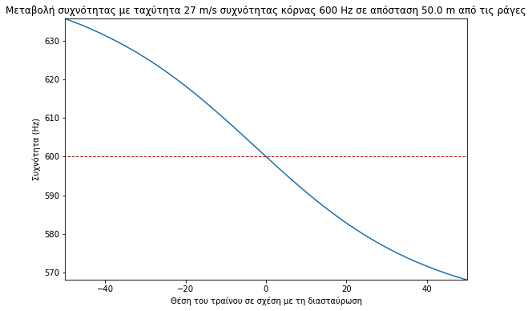

Βλέπετε τη μεταβολή της συχνότητας που φτάνει στα αυτιά μας, ας την ακούσουμε κιόλας!!

In [ ]:
# ΜΗ δώσετε σημασία στο τεχνικό κομμάτι των παρακάτω - αποτελούν ύλη άλλου μαθήματος - απλώς εκτελέστε τον κώδικα!
fs = 44100                       # Συχνότητα δειγματοληψίας.
w0 = 2 * np.pi * fnew / fs       # "Διακριτή συχνότητα".
n = np.arange(0, len(w0))        # Διάνυσμα διακριτού χρόνου.
output = np.cos(w0 * n)          # Ημίτονο !
Audio(output, rate=fs)           # Ακούμε! :)

### Ζητούμενο 2:

Παρακάτω σας δίνονται οι συχνότητες ενός πιο ρεαλιστικού ήχου κόρνας τραίνου, το οποίο μπορείτε να ακούσετε εδώ:

In [ ]:
fs, horn = wavfile.read('./horn.wav')     # Διαβάζουμε το συνοδευτικό wav αρχείο.
Audio(horn, rate=fs)                      # Ακούμε!

Οι συχνότητες που περιέχονται στο συνθετικό σήμα της κόρνας ακολουθούν παρακάτω, μαζί με τις υπόλοιπες παραμέτρους που είδατε και πριν. Γράψτε κώδικα που να εφαρμόζει το φαινόμενο Doppler στις παρακάτω συχνότητες. Αν τα κάνετε όλα σωστά, θα εμφανιστεί το γράφημα μεταβολής τους.

In [ ]:
# Συχνότητες σε Hz:
f1 = 277.18   # C#4
f2 = 329.63   # E4
f3 = 392.00   # G4
f4 = 466.16   # A#4
f5 = 554.37   # C#5

u = 340.0   # Ταχύτητα ήχου.
us = 30.0   # Ταχύτητα πηγής (τραίνου).
winmax = 300.0   # "Παράθυρο" παρατήρησης του φαινομένου Doppler.
d = np.arange(- winmax / 2, winmax / 2, 0.01)   # Παρατηρούμε από -150 ως 150 m εκατέρωθεν της διασταύρωσης.
b = 50.0   # Απόστασή μας από τη διασταύρωση.

ur = ((us * np.abs(d)) / np.sqrt(b ** 2 + d ** 2))   # Ακτινική ταχύτητα.

fnew1 = ((f1 * u) / (u + np.sign(d) * ur))     # Doppler effect 1.
fnew2 = ((f2 * u) / (u + np.sign(d) * ur))     # Doppler effect 2.
fnew3 = ((f3 * u) / (u + np.sign(d) * ur))     # Doppler effect 3.
fnew4 = ((f4 * u) / (u + np.sign(d) * ur))     # Doppler effect 4.
fnew5 = ((f5 * u) / (u + np.sign(d) * ur))     # Doppler effect 5.

plt.figure(figsize=(9, 6))
plt.axis([-winmax/2, winmax/2, 200, 650])
plt.plot(d, fnew1)
plt.plot(d, fnew2)
plt.plot(d, fnew3)
plt.plot(d, fnew4)
plt.plot(d, fnew5)
plt.ylabel("Συχνότητα (Hz)")
plt.xlabel("Θέση του τραίνου σε σχέση με τη διασταύρωση.")
plt.title("Μεταβολή συχνότητας με ταχύτητα {velocity:.0f} m/s κόρνας {frequency:.0f} Hz σε απόσταση {distance} m από τις ράγες.".format(velocity=us, distance=b, frequency=f))

#   plt.show()   # Γράφημα.

Αν έχετε περιέργεια να ακούσετε το Doppler-shifted σήμα της συνθετικής κόρνας, ιδού:

In [ ]:
fs, horn = wavfile.read('./DS_horn.wav')     # Διαβάζουμε το νέο συνοδευτικό wav αρχείο.
Audio(horn, rate=fs)                         # Ακούμε!

***

# Άσκηση Python 2

Σε αυτή την άσκηση θα δημιουργήσουμε μερικά κύματα και θα παρατηρήσουμε την αρχή της υπέρθεσης.

Θα χρησιμοποιήσουμε μια βιβλιοθήκη της Python για να μπορούμε να αυξομειώνουμε παραμέτρους και να βλέπουμε το αποτέλεσμά τους σε γραφική παράσταση. Από τη θεωρία γνωρίζουμε ότι ένα οδεύον ημιτονοειδές κύμα μπορεί να γραφεί ως

$$y(x,t) = A\sin\left(\frac{2\pi}{\lambda}(x \pm ut) + \phi\right)$$

ή αλλιώς

$$y(x,t) = A\sin\left(k(x \pm ut) + \phi\right)$$

Ακριβώς επειδή είναι μια τριδιάστατη αναπαράσταση, την οπτικοποιούμε είτε θέτοντας $t=t_0$ είτε $x=x_0$, παρατηρώντας πότε όλο το κύμα για μια συγκεκριμένη χρονική στιγμή, και πότε ένα στοιχείο του κύματος για κάθε χρονική στιγμή. 

Όμως μπορούμε να ζητήσουμε από την Python να μας βοηθήσει στην οπτικοποίηση, κατασκευάζοντας το ημιτονοειδές κύμα για ένα διάστημα $[x_1,x_2]$ ως συνάρτηση του χρόνου, και να χρησιμοποιήσουμε έναν slider για να βλέπουμε την αλλαγή του κύματος στο διάστημα αυτό όσο περνά ο χρόνος!!

Ας δούμε το παρακάτω παράδειγμα για ένα οδεύον κύμα προς τα δεξιά με παραμέτρους $k=10\pi$, $u=1$, $A=2$, $\phi=\pi/6$ και ας παρατηρήσουμε το κύμα στο διάστημα $[x_1, x_2] = [0,1]$. Απλά τρέξτε τον παρακάτω κώδικα και δείτε το αποτέλεσμα.

In [ ]:
@widgets.interact(t=(0, 2.0, 0.025))
def wavefunction_right(t=0):

    u = 1                    # Ταχύτητα κύματος.
    phi = np.pi / 6          # Αρχική φάση.
    A = 2                    # Πλάτος κύματος.
    lamda = 0.2              # Μήκος κύματος.
    k = 2 * np.pi / lamda    # Κυματαριθμός.

    x = np.linspace(0, 1.0, 1000)                # Κατασκευάζουμε τον άξονα x του κύματος, δηλ. όλο το κύμα για x=0 ως x=1.
    wave = A * np.sin(k * (x - u * t) + phi)     # Οδεύον κύμα προς τα δεξιά.

    plt.figure(figsize=(12, 4))
    plt.plot(x, wave, '-', color='blue')
    plt.ylim([-3, 3])
    plt.grid('on')
    plt.xlabel('x (θέση)')
    plt.ylabel('y(x)')
    plt.title('Κυματοσυνάρτηση y(x,t)')
    
#   plt.show()   # Γράφημα.

Στο παραπάνω γράφημα, μπορείτε να ολισθήσετε τον slider του χρόνου μεταξύ $0$ και $2$ δευτερόλεπτα, για να δείτε το κύμα για διαφορετικές χρονικές στιγμές! Με άλλα λόγια, μπορείτε να δείτε το κύμα να ταξιδεύει προς τα δεξιά όπως συμβαίνει στην πραγματικότητα!

### Ζητούμενο 1:

Χρησιμοποιήστε τον παραπάνω κώδικα για να φτιάξετε ένα γράφημα με δυο sliders:
* έναν για το μήκος κύματος $\lambda$, 
* κι έναν για το χρόνο $t$.

Το κύμα σας όμως θα είναι οδεύον **προς τα αριστερά** αυτή τη φορά! Οι παράμετροί του θα είναι 
* $A=2$, 
* $\phi=\pi$, 
* $u=1$, 
* $k=2\pi/\lambda$.

Συμπληρώστε κατάλληλα.

In [ ]:
@widgets.interact(lamda=(0.1, 1.0, 0.01), t=(0, 2.0, 0.025))
def wavefunction_left(t=0, lamda=0.1):

    u = 1                     # Ταχύτητα κύματος.
    phi = np.pi               # Αρχική φάση π.
    A = 2                     # Πλάτος κύματος.
    k = 2 * np.pi / lamda     # Κυματαριθμός.

    x = np.linspace(0, 1.0, 1000)                # Κατασκευάζουμε τον άξονα x του κύματος, δηλ. όλο το κύμα για x=0 ως x=1.
    wave = A * np.sin(k * (x + u * t) + phi)     # Οδεύον κύμα προς τα *αριστερά*.

    plt.figure(figsize=(12, 4))
    plt.plot(x, wave, '-', color='blue')
    plt.ylim([-3, 3])
    plt.grid('on')
    plt.xlabel('x (θέση)')
    plt.ylabel('y(x)')
    plt.title(f'Κυματοσυνάρτηση y(x,t) για λ={lamda:.2f} και t={t:.2f}.')
    
#   plt.show()   # Γράφημα.

Αυξομειώστε τους sliders και παρατηρήστε τι συμβαίνει.

### Ζητούμενο 2:

Χρησιμοποιήστε τον παραπάνω κώδικα για να φτιάξετε την **υπέρθεση δυο ημιτονοειδών κυμάτων που διαδίδονται προς τα δεξιά**. Τα κύματα θα έχουν ακριβώς τις ίδιες παραμέτρους, με εξαίρεση την αρχική φάση.

Φτιάξετε ένα γράφημα με **τρεις** sliders:
* έναν για το μήκος κύματος $\lambda$, κοινό και στα δυο κύματα
* έναν για την αρχική φάση $\phi$ ενός εκ των δυο κυμάτων (το άλλο θα έχει μηδενική φάση)
* κι έναν για το χρόνο $t$.

Οι παράμετροί τους θα είναι 
* $A=1$, 
* $u=1$, 
* $k=2\pi/\lambda$.

Συμπληρώστε κατάλληλα.

In [ ]:
@widgets.interact(lamda=(0.1,1.0,0.01), t=(0,2.0,0.025), phi=(0.0,2*np.pi,0.01))
def twowaves_right(t=0, lamda=0.1, phi=0.0):

    u = 1                     # Ταχύτητα κύματος.
    A = 1                     # Πλάτος κύματος.
    k = 2 * np.pi / lamda     # Κυματαριθμός.

    x = np.linspace(0, 1.0, 1000)                # Κατασκευάζουμε τον άξονα x του κύματος, δηλ. όλο το κύμα για x=0 ως x=1.
    wave1 = A * np.sin(k * (x - u * t) + phi)    # Πρώτο οδεύον κύμα προς τα δεξιά με φάση phi.
    wave2 = A * np.sin(k * (x - u * t) + 0)      # Δεύτερο οδεύον κύμα προς τα δεξιά χωρίς αρχική φάση (phi=0).

    plt.figure(figsize=(12, 6))
    plt.plot(x, wave1, '--', color='blue')
    plt.plot(x, wave2, '--', color='green')
    plt.plot(x, wave1 + wave2, color='red')

    plt.ylim([-3, 3])
    plt.legend(['y1(x,t)', 'y2(x,t)', 'Υπέρθεση'])
    plt.grid('on')
    
#   plt.show()   # Γράφημα.

Παρατηρήστε τι συμβαίνει όταν κρατάτε σταθερούς τους δυο πρώτους sliders και μετακινείτε μόνο το slider της φάσης. Πώς ονομάζονται τα κυματικά φαινόμενα όταν $\phi=0$ και $\phi=\pi$? **Αναφέρετε την απάντησή σας παρακάτω**.

• φ = 0: Ενισχητική Συμβολή Υπέρθρεης (κύματα σε φάση) !
• φ = π: Καταστρεπτική Συμβολή Υπέρθεσης (κύματα εκτός φάσης) !

### Ζητούμενο 3:

Τα ημιτονοειδή κύματα όπως τα παρουσιάσαμε παραπάνω διαδίδονται σε ευθεία γραμμή. Στην πραγματικότητα, τα ηχητικά κύματα διαδίδονται σφαιρικά στο χώρο, δηλ. περιγράφονται από τη συνάρτηση

$$y(r,t) = A\sin(kr \pm \omega t + \phi)$$

με $r$ την απόσταση από την ηχητική πηγή. Σε ένα επίπεδο, θα έχουμε
$$r = \sqrt{x^2 + y^2}$$

Αν υποθέσουμε ότι η διάδοση γίνεται στον ελεύθερο χώρο, σε ιδανικές συνθήκες, χωρίς ανακλάσεις κλπ., τότε είδαμε στις διαλέξεις πως ένα ακουστικό μονόπολο διαταράσσει τα μόρια του αέρα έτσι ώστε να διαδοθεί το ηχητικό κύμα. Επαναλαμβάνουμε το σχετικό σχήμα για ευκολία.

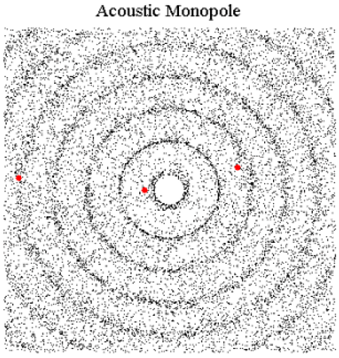

Ένα τέτοιο ηχητικό κύματα, διαδιδόμενο ισοτροπικά, έχει την ίδια ένταση σε απόσταση $r$ από την πηγή, και είναι ανάλογη του πλάτους του κύματος στο τετράγωνο:

$$I = \frac{P}{4\pi r^2} \propto A^2$$

με $P$ τη μέση ισχύ της πηγής. 

Χάριν ευκολίας για την άσκηση, ας υποθέσουμε ότι δεν υπάρχει απώλεια έντασης λόγω της απόστασης, και ότι το ηχητικό κύμα είναι έντασης ανεξάρτητης της απόστασης.

Ας φτιάξουμε ένα ακουστικό μονόπολο και ας δούμε την κυματική διάδοση σε μορφή κυματικών μετώπων στο επίπεδο. Υποθέτουμε το ηχητικό κύμα της μορφής

$$y(r,t) = A\sin\left(kr - \omega t + \phi\right) = 2\sin\left(\frac{2\pi}{0.5}r - \frac{2\pi}{5}t\right)$$

Ας φτιάξουμε ένα "πλέγμα" του $xy-$επιπέδου, επιλέγοντας αρκετά "πυκνά" διάφορες συντεταγμένες αυτού του επιπέδου. Για ευκολία, ας θεωρήσουμε ότι το "πλέγμα" μας θα βρίσκεται εντός του υπο-επιπέδου $[-2,2] \times [-2,2]$. 

Θα χρησιμοποιήσουμε τον παρακάτω κώδικα μαζί με έναν slider για να βλέπουμε την κυματική διάδοση γύρω από το μονόπολο για διάφορες χρονικές στιγμές. Εκτελέστε τον παρακάτω κώδικα.

In [ ]:
@widgets.interact(t=(0, 2, 0.01))
def monopole(t=0.0):

    A = 2                   # Πλάτος.
    w = 2 * np.pi * 5       # Γωνιακή συχνότητα 2π/5.
    k = 2 * np.pi / 0.5     # Κυματαριθμός 2π/0.5.
    phi = 0.0               # Αρχική φάση.

    nx, ny = 64, 64                # Θα ζητήσουμε 64 σημεία x 64 σημεία στο υποεπίπεδο [-2,2]x[-2,2].
    x = np.linspace(-2, 2, nx)     # Φτιάχνουμε τον άξονα x'x του υποεπιπέδου.
    y = np.linspace(-2, 2, ny)     # Φτιάχνουμε τον άξονα y'y του υποεπιπέδου.
    X, Y = np.meshgrid(x, y)       # Καλούμε τη συνάρτηση meshgrid της numpy που μας φτιάχνει το "πλέγμα" 64x64 σημείων εντός του [-2,2]x[-2,2].

    r = np.sqrt(X ** 2 + Y ** 2)     # Ακτίνα r από το μονόπολο.

    S = A * np.sin(k * r - w * t + phi)     # Κυματοσυνάρτηση.

    fig = plt.figure(figsize=(6, 6))
    plt.contourf(X, Y, S, 40, cmap='plasma')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Μονόπολο')

#   fig.show()   # Γράφημα.

Όταν έχουμε όμως **περισσότερες από μια** ηχητική πηγή στον ίδιο χώρο, τα ηχητικά κύματα **συμβάλλουν**! Αυτό σημαίνει ότι η υπέρθεσή τους μπορεί να είναι καταστρεπτική (το άθροισμα των δυο κυμάτων να δίνει μηδενικό κύμα), ενισχυτική (το άθροισμα των δυο κυμάτων να δίνει κύμα με μέγιστο πλάτος), ή ενδιάμεση (το άθροισμα των δυο κυμάτων δίνει κύμα με πλάτος ανάμεσα στο μηδεν και στο μέγιστο δυνατό). Δείτε το παρακάτω σχήμα.

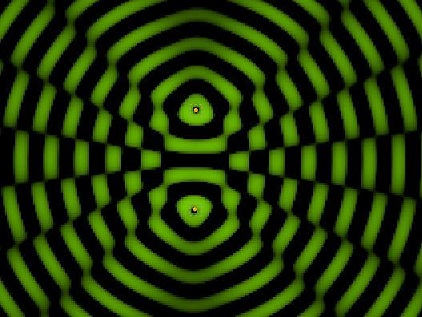

Το παραπάνω σχήμα ονομάζεται **διάγραμμα παρεμβολής (interference pattern)**.

Σας ζητείται να συμπληρώσετε την παρακάτω συνάρτηση η οποία παράγει το διάγραμμα παρεμβολής για δυο ηχητικές πηγές που βρίσκονται στις θέσεις $(-1,0)$ και $(1,0)$ στο επίπεδο $(x,y)$. Θα χρησιμοποιήσουμε έναν slider για να βλέπουμε πως αλλάζει το διάγραμμα παρεμβολής συναρτήσει του χρόνου.

In [ ]:
@widgets.interact(t=(0, 2, 0.0025))
def interference_two_sources(t=0.0):

    A = 2                                         # Πλάτος.
    w = 2 * np.pi * 5                             # Γωνιακή συχνότητα 2π/5.
    k = 2 * np.pi / 0.5                           # Κυματαριθμός 2π/0.5.
    phi = 0.0                                     # Αρχική φάση.

    nx, ny = 64, 64                               # Θα ζητήσουμε 64 σημεία x 64 σημεία στο υποεπίπεδο [-2,2]x[-2,2].
    x = np.linspace(-2, 2, nx)                    # Φτιάχνουμε τον άξονα x'x του υποεπιπέδου.
    y = np.linspace(-2, 2, ny)                    # Φτιάχνουμε τον άξονα y'y του υποεπιπέδου.
    X, Y = np.meshgrid(x, y)                      # Καλούμε τη meshgrid της numpy που μας φτιάχνει το "πλέγμα" 64x64 σημείων εντός του [-2,2]x[-2,2].

    x1, y1 = -1, 0                                # Οι συντεταγμένες της πρώτης ηχητικής πηγής.
    x2, y2 = 1, 0                                 # Οι συντεταγμένες της δεύτερης ηχητικής πηγής.

    r1 = np.sqrt((X - x1) ** 2 + (Y - y1) ** 2)   # Ακτίνα κύκλου με κέντρο το (x1,y1).
    r2 = np.sqrt((X - x2) ** 2 + (Y - y2) ** 2)   # Ακτίνα κύκλου με κέντρο το (x2,y2).

    S1 = A * np.sin(k * r1 - w * t + phi)         # Πρώτη κυματοσυνάρτηση.
    S2 = A * np.sin(k * r2 - w * t + phi)         # Δεύτερη κυματοσυνάρτηση.

    S = S1 + S2                                   # Υπέρθεση των δυο κυματοσυναρτήσεων.

    fig = plt.figure(figsize=(6, 6))
    plt.contourf(X, Y, S, 40, cmap='plasma')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Ακουστικό δίπολο')

#   fig.show()   # Γράφημα.

Αν τα κάνετε όλα σωστά, θα σας εμφανιστεί το παρακάτω σχήμα.

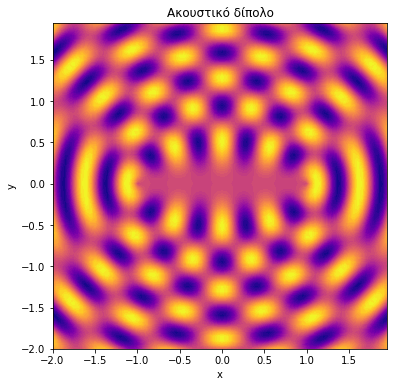

Μπορείτε να ολισθήσετε τον slider για να δείτε πως μεταβάλλεται το διάγραμμα παρεμβολής όσο περνά ο χρόνος! 

### Ζητούμενο 4:

Τέλος, είδαμε στη θεωρία ότι αν τοποθετήσουμε δυο ηχητικές πηγές τη μια απέναντι στην άλλη, τότε τα δυο ηχητικά κύματα δημιουργούν ένα **στάσιμο** κύμα. Θα χρησιμοποιήσουμε τον κώδικα προηγούμενου ζητούμενου για να δημιουργήσουμε ένα στάσιμο κύμα. 

Συμπληρώστε τον κώδικα κατάλληλα ώστε το αποτέλεσμα να είναι ένα στάσιμο κύμα! Θυμηθείτε ότι το μόνο που χρειάζεστε είναι δυο κύματα που οδεύουν προς αντίθετες κατευθύνσεις!

In [ ]:
@widgets.interact(t=(0, 1.0, 0.01))
def standing_wave(t=0):

    u = 1                   # Ταχύτητα κύματος.
    A = 1                   # Πλάτος κύματος.
    lamda = 0.5             # Μήκος κύματος.
    k = 2 * np.pi / lamda   # Κυματαριθμός.

    x = np.linspace(0, 1.0, 1000)   # Κατασκευάζουμε τον άξονα x του κύματος, δηλ. όλο το κύμα για x=0 ως x=1.

    wave1 = (A * np.sin(k * x - 2 * np.pi * u * t))   # Οδεύον κύμα προς τα δεξιά.
    wave2 = (A * np.sin(k * x + 2 * np.pi * u * t))   # Οδεύον κύμα προς τα αριστερά.

    plt.figure(figsize=(12, 6))
    plt.plot(x, wave1, '--', color='blue')
    plt.plot(x, wave2, '--', color='green')
    plt.plot(x, wave1 + wave2, color='red')

    plt.ylim([-3, 3])
    plt.legend(['y1(x,t)', 'y2(x,t)', 'Στάσιμο κύμα'])
    plt.grid('on')

#   plt.show()   # Γράφημα.

***
***
## Παραδοτέα:
*** 
### Μετονομάστε το **συμπληρωμένο και με εκτελεσμένο κάθε κελί κώδικα** notebook σε 

## *ΗΥ112-HW5-Python-CSDXXXX.ipynb*, 

### με *XXXX* ο αριθμός μητρώου σας. 

### Αν είστε με προσωρινό κωδικό λόγω μεταγραφής, τότε ονομάστε το αρχείο σας 

## *ΗΥ112-HW5-Python-mtgXXXX.ipynb*, 

### με *XXXX* ο προσωρινός αριθμός μητρώου σας.

### Στείλτε το μετονομασμένο notebook ως επισυναπτόμενο αρχείο με e-mail στο bzotos@csd.uoc.gr . 

### Στο e-mail θα αναγράφετε:

### - Τίτλος: [ΗΥ112] 5ο εργαστήριο Python

### και στο σώμα του e-mail τα παρακάτω: 

### - Ονοματεπώνυμο
### - ΑΜ

### ΠΡΟΣΕΞΤΕ: Το παραδοτέο αρχείο σας πρέπει να έχει extension .ipynb, και ΟΧΙ κάτι άλλο!!